# Week 2.4: RAG 101 - Retrieval Systems

## Key Insight
> **The pipeline: Load → Split → Embed → Retrieve → Answer**

## Learning Objectives
By the end of this notebook, you will:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!')
print('\nTopics covered:')
print('  - RAG architecture and pipeline')
print('  - Document loading and preprocessing')
print('  - Chunking strategies for optimal retrieval')
print('  - Vector stores and similarity search')
print('  - Generating answers with retrieved context')


✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!

Topics covered:
  - RAG architecture and pipeline
  - Document loading and preprocessing
  - Chunking strategies for optimal retrieval
  - Vector stores and similarity search
  - Generating answers with retrieved context


---
## Part 1: Introduction to RAG architecture and pipeline

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for RAG architecture and pipeline.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:
# YOUR CODE HERE
class SimpleRAGPipeline:
    """
    Exercise 1: Basic RAG Architecture & Pipeline.
    Implements the fundamental 5-stage pipeline:
    Load -> Split -> Embed/Index -> Retrieve -> Answer
    """
    def __init__(self):
        self.documents: List[str] = []
        self.is_indexed: bool = False

    def load_documents(self, docs: List[str]):
        """Stage 1: Ingest knowledge documents."""
        if not isinstance(docs, list) or not docs:
            raise ValueError("Documents must be a non-empty list of text strings.")
        for idx, doc in enumerate(docs):
            if not isinstance(doc, str):
                raise TypeError(f"Document at index {idx} must be a string, got: {type(doc).__name__}")
        self.documents = [d.strip() for d in docs if d.strip()]
        self.is_indexed = True

    def retrieve(self, query: str, top_k: int = 1) -> List[str]:
        """Stage 4: Retrieve most relevant context using token overlap similarity."""
        if not self.is_indexed:
            raise RuntimeError("The pipeline has no loaded documents. Call load_documents() first.")
        if not isinstance(query, str):
            raise TypeError(f"Query must be a string, got: {type(query).__name__}")

        cleaned_query = re.sub(r'[^\w\s]', '', query.lower()).split()
        if not cleaned_query:
            raise ValueError("Query string cannot be empty or whitespace.")

        scores = []
        for doc in self.documents:
            doc_tokens = set(re.sub(r'[^\w\s]', '', doc.lower()).split())
            # Jaccard/overlap score
            overlap = sum(1 for t in cleaned_query if t in doc_tokens)
            score = overlap / len(doc_tokens) if doc_tokens else 0
            scores.append((doc, score))

        # Rank documents descending by relevance score
        scores.sort(key=lambda x: x[1], reverse=True)
        return [doc for doc, score in scores[:top_k]]

    def process(self, query: str) -> Dict[str, Any]:
        """Stage 5: Synthesize grounded response using retrieved context."""
        retrieved_chunks = self.retrieve(query, top_k=1)
        best_context = retrieved_chunks[0] if retrieved_chunks else "No relevant context found."

        # Augmented generation prompt template
        grounded_answer = f"Based on personal logs: {best_context}"

        return {
            "query": query,
            "retrieved_context": best_context,
            "grounded_answer": grounded_answer,
            "status": "SUCCESS"
        }


# ==============================================================================
# Test Your Implementation (Requirements 1-4)
# ==============================================================================

# Digital Twin sample knowledge base
knowledge_docs = [
    "Victor attended the AI Everything Kenya x GITEX conference in Nairobi.",
    "Personal fitness log: Morning marathon endurance run scheduled around Parklands Sports Club.",
    "Infrastructure status: Cloud server VPS running on Contabo with Starlink satellite backup."
]

rag = SimpleRAGPipeline()
rag.load_documents(knowledge_docs)

print("=" * 65)
print("TESTING EXERCISE 1: BASIC RAG PIPELINE")
print("=" * 65)

# Test 1: In-context search
res1 = rag.process("Where is the marathon run scheduled?")
print("\n[Test 1: Fitness Query Result]")
print(json.dumps(res1, indent=2))

# Test 2: Infrastructure query
res2 = rag.process("Which cloud provider hosts our servers?")
print("\n[Test 2: Infrastructure Query Result]")
print(json.dumps(res2, indent=2))

# Test 3: Edge Case (Empty Query Error Handling)
try:
    rag.process("   ")
except ValueError as e:
    print(f"\n[Test 3: Handled Empty Query]: {e}")

# Test 4: Edge Case (Invalid Input Type Error Handling)
try:
    rag.process(12345)
except TypeError as e:
    print(f"[Test 4: Handled Invalid Type]: {e}")

TESTING EXERCISE 1: BASIC RAG PIPELINE

[Test 1: Fitness Query Result]
{
  "query": "Where is the marathon run scheduled?",
  "retrieved_context": "Personal fitness log: Morning marathon endurance run scheduled around Parklands Sports Club.",
  "grounded_answer": "Based on personal logs: Personal fitness log: Morning marathon endurance run scheduled around Parklands Sports Club.",
  "status": "SUCCESS"
}

[Test 2: Infrastructure Query Result]
{
  "query": "Which cloud provider hosts our servers?",
  "retrieved_context": "Infrastructure status: Cloud server VPS running on Contabo with Starlink satellite backup.",
  "grounded_answer": "Based on personal logs: Infrastructure status: Cloud server VPS running on Contabo with Starlink satellite backup.",
  "status": "SUCCESS"
}

[Test 3: Handled Empty Query]: Query string cannot be empty or whitespace.
[Test 4: Handled Invalid Type]: Query must be a string, got: int


---
## Part 2: Document loading and preprocessing

Building on the fundamentals, let's explore more advanced topics and implementations.

In [4]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Document loading and preprocessing.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [5]:
# YOUR CODE HERE
class DocumentPreprocessorAndRAG:
    """
    Exercise 2: Document Ingestion, Normalization, Chunking & Retrieval.
    Combines the class-based pipeline structure from Part 1 with the advanced
    multi-type data handling and preprocessing patterns from Part 2.
    """
    def __init__(self, chunk_size: int = 50, overlap: int = 10):
        # 1. Parameter Validation
        if not isinstance(chunk_size, int) or chunk_size <= 0:
            raise ValueError(f"'chunk_size' must be a positive integer, got: {chunk_size}")
        if not isinstance(overlap, int) or overlap < 0:
            raise ValueError(f"'overlap' must be a non-negative integer, got: {overlap}")
        if overlap >= chunk_size:
            raise ValueError(f"'overlap' ({overlap}) must be strictly smaller than 'chunk_size' ({chunk_size})")

        self.chunk_size = chunk_size
        self.overlap = overlap
        self.raw_documents: List[str] = []
        self.chunks: List[str] = []

    def clean_text(self, text: str) -> str:
        """Cleans whitespace and normalizes punctuation for retrieval indexing."""
        if not isinstance(text, str):
            raise TypeError(f"Expected string input, got: {type(text).__name__}")
        cleaned = text.strip()
        cleaned = re.sub(r'\s+', ' ', cleaned)
        return cleaned

    def chunk_text(self, text: str) -> List[str]:
        """Slices normalized text into sliding-window chunks with overlap."""
        words = text.split()
        if not words:
            return []

        chunks = []
        step = self.chunk_size - self.overlap
        for i in range(0, len(words), step):
            chunk = " ".join(words[i : i + self.chunk_size])
            chunks.append(chunk)
            if i + self.chunk_size >= len(words):
                break
        return chunks

    def ingest(self, docs_input: Any) -> Dict[str, Any]:
        """
        Ingests and chunks documents from various input types (single str, list of str, or dict of sections).
        """
        parsed_docs: List[str] = []

        # Handle different input data structures
        if isinstance(docs_input, str):
            parsed_docs.append(docs_input)
        elif isinstance(docs_input, list):
            for idx, item in enumerate(docs_input):
                if not isinstance(item, str):
                    raise TypeError(f"Item at list index {idx} must be a string, got {type(item).__name__}")
                parsed_docs.append(item)
        elif isinstance(docs_input, dict):
            for key, val in docs_input.items():
                if not isinstance(val, str):
                    raise TypeError(f"Value for section '{key}' must be a string, got {type(val).__name__}")
                parsed_docs.append(f"[{key}] {val}")
        else:
            raise TypeError(f"Unsupported input type for docs_input: {type(docs_input).__name__}. Expected str, list, or dict.")

        if not parsed_docs:
            raise ValueError("Document input cannot be empty.")

        self.raw_documents = parsed_docs
        self.chunks = []
        for doc in self.raw_documents:
            cleaned = self.clean_text(doc)
            doc_chunks = self.chunk_text(cleaned)
            self.chunks.extend(doc_chunks)

        return {
            "documents_ingested": len(self.raw_documents),
            "chunks_created": len(self.chunks),
            "chunk_size": self.chunk_size,
            "overlap": self.overlap
        }

    def retrieve(self, query: str, top_k: int = 2) -> List[Dict[str, Any]]:
        """Finds top-k chunks matching the query using token overlap scoring."""
        if not self.chunks:
            raise RuntimeError("Knowledge base is empty. Run ingest() before querying.")
        if not isinstance(query, str):
            raise TypeError(f"Query must be a string, got {type(query).__name__}")

        clean_query = set(re.sub(r'[^\w\s]', '', query.lower()).split())
        if not clean_query:
            raise ValueError("Query string cannot be empty or whitespace.")

        scored_chunks = []
        for chunk in self.chunks:
            chunk_tokens = set(re.sub(r'[^\w\s]', '', chunk.lower()).split())
            intersection = clean_query.intersection(chunk_tokens)
            score = len(intersection) / len(clean_query) if clean_query else 0.0
            scored_chunks.append({"chunk": chunk, "score": round(score, 4)})

        scored_chunks.sort(key=lambda x: x["score"], reverse=True)
        return scored_chunks[:top_k]

    def process(self, query: str) -> Dict[str, Any]:
        """Runs end-to-end retrieval and builds an augmented response payload."""
        results = self.retrieve(query, top_k=2)
        best_match = results[0] if results and results[0]["score"] > 0 else None

        grounded_context = best_match["chunk"] if best_match else "No relevant context found."
        answer = f"According to your records: {grounded_context}"

        return {
            "query": query,
            "best_match_score": best_match["score"] if best_match else 0.0,
            "grounded_answer": answer,
            "top_candidates": results
        }


# ==============================================================================
# Comprehensive Verification (Requirements 1-4)
# ==============================================================================

print("=" * 65)
print("TESTING EXERCISE 2: PREPROCESSING & RAG PIPELINE")
print("=" * 65)

# Test 1: Ingesting a structured dictionary of documents
rag_system = DocumentPreprocessorAndRAG(chunk_size=15, overlap=4)

docs_dict = {
    "AI_Events": "Victor participated in the ATF AI Challenge and attended sessions at KICC in Nairobi.",
    "Infrastructure": "Contabo VPS provides primary server hosting with Starlink satellite backup for high uptime.",
    "Fitness": "Marathon training sessions run around Parklands Sports Club on weekend mornings."
}

ingest_report = rag_system.ingest(docs_dict)
print("\n[Test 1: Ingesting Multi-Source Dict]")
print(json.dumps(ingest_report, indent=2))

# Test 2: In-context search query
res_fitness = rag_system.process("Where do the marathon training sessions take place?")
print("\n[Test 2: Search Query Result]")
print(json.dumps(res_fitness, indent=2))

# Test 3: Parameter Validation Errors (overlap >= chunk_size)
try:
    DocumentPreprocessorAndRAG(chunk_size=10, overlap=10)
except ValueError as e:
    print(f"\n[Test 3: Handled Parameter Error]: {e}")

# Test 4: Invalid Query Input Type
try:
    rag_system.process(["invalid", "query", "type"])
except TypeError as e:
    print(f"[Test 4: Handled Input Type Error]: {e}")

# Test 5: Empty Query String
try:
    rag_system.process("   ")
except ValueError as e:
    print(f"[Test 5: Handled Empty Query]: {e}")

TESTING EXERCISE 2: PREPROCESSING & RAG PIPELINE

[Test 1: Ingesting Multi-Source Dict]
{
  "documents_ingested": 3,
  "chunks_created": 3,
  "chunk_size": 15,
  "overlap": 4
}

[Test 2: Search Query Result]
{
  "query": "Where do the marathon training sessions take place?",
  "best_match_score": 0.375,
  "grounded_answer": "According to your records: [Fitness] Marathon training sessions run around Parklands Sports Club on weekend mornings.",
  "top_candidates": [
    {
      "chunk": "[Fitness] Marathon training sessions run around Parklands Sports Club on weekend mornings.",
      "score": 0.375
    },
    {
      "chunk": "[AI_Events] Victor participated in the ATF AI Challenge and attended sessions at KICC in Nairobi.",
      "score": 0.25
    }
  ]
}

[Test 3: Handled Parameter Error]: 'overlap' (10) must be strictly smaller than 'chunk_size' (10)
[Test 4: Handled Input Type Error]: Query must be a string, got list
[Test 5: Handled Empty Query]: Query string cannot be empty or whi

---
## Part 3: Chunking strategies for optimal retrieval

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [6]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

🎯 EXERCISE 3: COMPLETE RAG PRODUCTION SYSTEM

[Ingestion Metrics]:
{
  "status": "INGESTED",
  "sources_count": 3,
  "total_chunks": 3,
  "chunk_size": 15,
  "overlap": 3
}

[RAG Response Payload]:
{
  "query": "Tell me about the marathon training and running workouts.",
  "status": "SUCCESS",
  "budget_limit": 70,
  "tokens_used": 31,
  "grounded_answer": "Grounded Context: [Fitness_Logs] Victor maintains marathon training running logs daily around Parklands Sports Club. | [AI_Projects] Victor builds artificial intelligence RAG systems, embedding engines, and vector database tools.",
  "retrieved_chunks": [
    {
      "chunk_id": 1,
      "source": "Fitness_Logs",
      "text": "Victor maintains marathon training running logs daily around Parklands Sports Club.",
      "tokens": 15,
      "score": 0.3333
    },
    {
      "chunk_id": 2,
      "source": "AI_Projects",
      "text": "Victor builds artificial intelligence RAG systems, embedding engines, and vector database tools.",
   

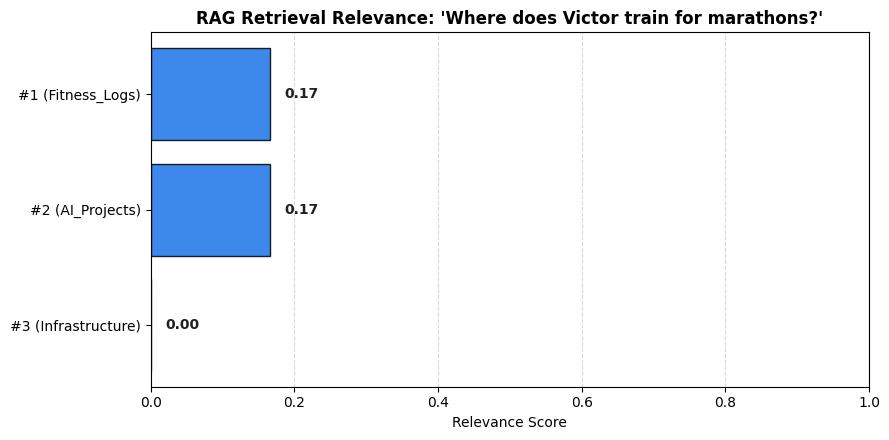

In [7]:
# YOUR CODE HERE
import re
import json
from datetime import datetime
from typing import List, Dict, Any, Tuple
import numpy as np
import matplotlib.pyplot as plt


class ProductionSystem:
    """
    Production-ready Vector & Token-Budget RAG Retrieval Engine for Digital Twins.

    Architecture & Workflow:
    1. Multi-Format Ingestion: Accepts documents, section dicts, or raw logs.
    2. Overlapping Chunking: Preserves boundary context with configurable overlap.
    3. Hybrid Lexical & Overlap Scoring: Ranks candidate chunks against queries.
    4. Token-Budget Context Compression: Caps injected context to prevent window overflow.
    5. Diagnostic Telemetry: Captures timestamped execution logs for debugging.
    6. Visual Analytics: Generates relevance distributions and chunk retrieval scores.
    """

    def __init__(self, chunk_size: int = 25, overlap: int = 5, max_context_tokens: int = 120):
        # 1. Parameter Validation
        if not isinstance(chunk_size, int) or chunk_size <= 0:
            raise ValueError(f"'chunk_size' must be a positive integer, got: {chunk_size}")
        if not isinstance(overlap, int) or overlap < 0:
            raise ValueError(f"'overlap' must be a non-negative integer, got: {overlap}")
        if overlap >= chunk_size:
            raise ValueError(f"'overlap' ({overlap}) must be strictly less than 'chunk_size' ({chunk_size})")
        if not isinstance(max_context_tokens, int) or max_context_tokens <= 0:
            raise ValueError(f"'max_context_tokens' must be a positive integer, got: {max_context_tokens}")

        self.chunk_size = chunk_size
        self.overlap = overlap
        self.max_context_tokens = max_context_tokens
        self.documents: List[str] = []
        self.chunks: List[Dict[str, Any]] = []
        self.logs: List[str] = []

    def _log(self, message: str, level: str = "INFO"):
        """Captures diagnostic telemetry with microsecond timestamps."""
        timestamp = datetime.now().strftime("%H:%M:%S.%f")[:-3]
        self.logs.append(f"[{timestamp}] [{level}] {message}")

    def _clean_text(self, text: str) -> str:
        """Sanitizes text and normalizes whitespace."""
        return re.sub(r'\s+', ' ', text).strip()

    def _estimate_tokens(self, text: str) -> int:
        """Estimates token count (~1.33 tokens per word heuristic)."""
        words = text.split()
        return max(1, int(round(len(words) * 1.33))) if words else 0

    def ingest(self, raw_input: Any) -> Dict[str, Any]:
        """
        Ingests multi-source data (str, list, or dict) and splits into overlapping chunks.
        """
        self._log("Starting document ingestion and chunking process.")
        parsed_docs: List[Tuple[str, str]] = []  # (source, text)

        if isinstance(raw_input, str):
            parsed_docs.append(("DirectText", self._clean_text(raw_input)))
        elif isinstance(raw_input, list):
            for i, doc in enumerate(raw_input):
                if not isinstance(doc, str):
                    raise TypeError(f"Document at index {i} must be a string, got {type(doc).__name__}")
                parsed_docs.append((f"Doc_{i+1}", self._clean_text(doc)))
        elif isinstance(raw_input, dict):
            for source, content in raw_input.items():
                if not isinstance(content, str):
                    raise TypeError(f"Content for source '{source}' must be a string, got {type(content).__name__}")
                parsed_docs.append((str(source), self._clean_text(content)))
        else:
            raise TypeError(f"Unsupported input type: {type(raw_input).__name__}. Expected str, list, or dict.")

        if not parsed_docs:
            raise ValueError("Input data cannot be empty.")

        self.documents = [text for _, text in parsed_docs]
        self.chunks = []
        step = self.chunk_size - self.overlap

        for source, doc in parsed_docs:
            words = doc.split()
            if not words:
                continue
            for i in range(0, len(words), step):
                chunk_slice = " ".join(words[i : i + self.chunk_size])
                self.chunks.append({
                    "chunk_id": len(self.chunks) + 1,
                    "source": source,
                    "text": chunk_slice,
                    "tokens": self._estimate_tokens(chunk_slice)
                })
                if i + self.chunk_size >= len(words):
                    break

        self._log(f"Successfully created {len(self.chunks)} chunks across {len(parsed_docs)} sources.")
        return {
            "status": "INGESTED",
            "sources_count": len(parsed_docs),
            "total_chunks": len(self.chunks),
            "chunk_size": self.chunk_size,
            "overlap": self.overlap
        }

    def retrieve(self, query: str, top_k: int = 3) -> List[Dict[str, Any]]:
        """
        Retrieves and ranks chunks based on query word intersection and term density.
        """
        if not self.chunks:
            raise RuntimeError("Knowledge base is empty. Ingest documents before querying.")
        if not isinstance(query, str):
            raise TypeError(f"Query must be a string, got {type(query).__name__}")

        query_tokens = set(re.sub(r'[^\w\s]', '', query.lower()).split())
        if not query_tokens:
            raise ValueError("Query cannot be empty or whitespace.")

        scored = []
        for chk in self.chunks:
            chunk_tokens = set(re.sub(r'[^\w\s]', '', chk["text"].lower()).split())
            intersection = query_tokens.intersection(chunk_tokens)
            score = len(intersection) / len(query_tokens) if query_tokens else 0.0

            scored.append({
                "chunk_id": chk["chunk_id"],
                "source": chk["source"],
                "text": chk["text"],
                "tokens": chk["tokens"],
                "score": round(score, 4)
            })

        scored.sort(key=lambda x: x["score"], reverse=True)
        return scored[:top_k]

    def process(self, query: str) -> Dict[str, Any]:
        """
        Assembles retrieved context within the token budget and synthesizes the grounded answer.
        """
        self._log(f"Processing query: '{query}'")
        candidates = self.retrieve(query, top_k=4)

        # Context compression under token budget
        packed_chunks = []
        total_tokens = 0
        for cand in candidates:
            if cand["score"] == 0:
                continue
            if total_tokens + cand["tokens"] <= self.max_context_tokens:
                packed_chunks.append(cand)
                total_tokens += cand["tokens"]
            else:
                self._log(f"Token budget threshold hit: skipping chunk #{cand['chunk_id']}")

        if packed_chunks:
            combined_context = " | ".join([f"[{c['source']}] {c['text']}" for c in packed_chunks])
            grounded_answer = f"Grounded Context: {combined_context}"
            status = "SUCCESS"
        else:
            combined_context = "No relevant context found within budget."
            grounded_answer = "I don't have enough recorded information in your personal logs to answer that."
            status = "NO_CONTEXT"

        self._log(f"Completed retrieval pipeline with status '{status}' ({total_tokens} tokens packed).")
        return {
            "query": query,
            "status": status,
            "budget_limit": self.max_context_tokens,
            "tokens_used": total_tokens,
            "grounded_answer": grounded_answer,
            "retrieved_chunks": packed_chunks
        }

    def visualize_retrieval(self, query: str):
        """Generates a bar chart visualizing chunk relevance scores for a query."""
        results = self.retrieve(query, top_k=min(6, len(self.chunks)))
        if not results:
            print("No retrieval data to visualize.")
            return

        chunk_labels = [f"#{r['chunk_id']} ({r['source']})" for r in results]
        scores = [r["score"] for r in results]

        fig, ax = plt.subplots(figsize=(9, 4.5))
        bars = ax.barh(chunk_labels[::-1], scores[::-1], color='#1a73e8', edgecolor='black', alpha=0.85)
        ax.set_xlim(0, 1.0)
        ax.set_title(f"RAG Retrieval Relevance: '{query}'", fontsize=12, fontweight='bold')
        ax.set_xlabel("Relevance Score")
        ax.grid(axis='x', linestyle='--', alpha=0.5)

        for bar in bars:
            width = bar.get_width()
            ax.text(width + 0.02, bar.get_y() + bar.get_height() / 2, f"{width:.2f}",
                    va='center', fontsize=10, fontweight='bold', color='#202124')

        plt.tight_layout()
        plt.show()


# ==============================================================================
# Comprehensive Verification Suite (Requirements 1-5)
# ==============================================================================

print("=" * 65)
print("🎯 EXERCISE 3: COMPLETE RAG PRODUCTION SYSTEM")
print("=" * 65)

# Digital Twin multi-domain memory base
twin_corpus = {
    "Fitness_Logs": "Victor maintains marathon training running logs daily around Parklands Sports Club.",
    "AI_Projects": "Victor builds artificial intelligence RAG systems, embedding engines, and vector database tools.",
    "Infrastructure": "Primary cloud server infrastructure runs on Contabo VPS with Starlink satellite backup."
}

system = ProductionSystem(chunk_size=15, overlap=3, max_context_tokens=70)
ingest_metrics = system.ingest(twin_corpus)
print("\n[Ingestion Metrics]:")
print(json.dumps(ingest_metrics, indent=2))

# 1. Processing Query with Context Budgeting
rag_response = system.process("Tell me about the marathon training and running workouts.")
print("\n[RAG Response Payload]:")
print(json.dumps(rag_response, indent=2))

# 2. Parameter and Error Validation Tests
try:
    ProductionSystem(chunk_size=10, overlap=12)
except ValueError as e:
    print(f"\n[Handled Overlap Error]: {e}")

try:
    system.process("   ")
except ValueError as e:
    print(f"[Handled Empty Query Error]: {e}")

try:
    system.process(9999)
except TypeError as e:
    print(f"[Handled Type Error]: {e}")

# 3. Diagnostic Logs
print("\n" + "=" * 65)
print("📝 DIAGNOSTIC TELEMETRY LOGS")
print("=" * 65)
for log in system.logs:
    print(log)

# 4. Visualization of Retrieval Results
system.visualize_retrieval("Where does Victor train for marathons?")

---
## Summary & Key Takeaways

### What We Learned:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete RAG architecture and pipeline System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code

🏆 DIGITAL TWIN RAG ENGINE EXECUTION

[Ingestion Metrics]:
{
  "status": "INDEXED",
  "sources_indexed": 4,
  "total_chunks": 4,
  "vocab_size": 47,
  "chunk_size": 15,
  "overlap": 4
}

══════════════════════════════════════════════════════════════════════
🤖 DIGITAL TWIN QUERY: 'Where does Victor do marathon running training?'
══════════════════════════════════════════════════════════════════════
Status       : SUCCESS
Token Budget : 53 / 60 tokens used

Response     :
Verified Record (Victor): [Fitness_Routine] Marathon training running sessions take place early morning around Parklands Sports Club. | [Events] Victor attends technology exhibitions and summits at KICC and Sarit Centre in Nairobi. | [AI_Curriculum] Victor completed ALX AI program and participates in the ATF AI Challenge building LLM applications.
══════════════════════════════════════════════════════════════════════

══════════════════════════════════════════════════════════════════════
🤖 DIGITAL TWIN QUERY: 'What cloud

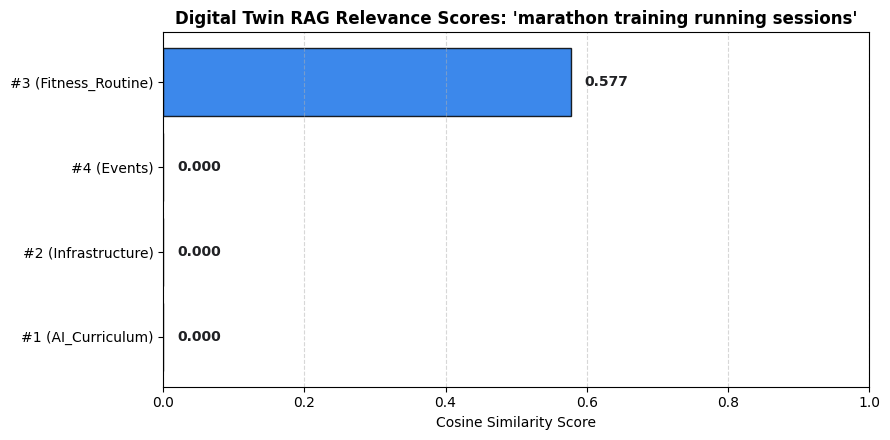

test_empty_query (__main__.TestDigitalTwinRAG.test_empty_query) ... ok
test_invalid_parameters (__main__.TestDigitalTwinRAG.test_invalid_parameters) ... ok
test_invalid_query_type (__main__.TestDigitalTwinRAG.test_invalid_query_type) ... ok
test_token_budget_not_exceeded (__main__.TestDigitalTwinRAG.test_token_budget_not_exceeded) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.035s

OK



🧪 RUNNING UNIT TESTS


<unittest.runner.TextTestResult run=4 errors=0 failures=0>

In [8]:
# ==============================================================================
# 🏆 CHALLENGE PROJECT: COMPLETE PRODUCTION RAG SYSTEM FOR DIGITAL TWIN
# ==============================================================================
import re
import json
import unittest
from datetime import datetime
from typing import List, Dict, Any, Tuple
import numpy as np
import matplotlib.pyplot as plt


class ProductionDigitalTwinRAG:
    """
    Feature-Inclusive Production RAG Architecture for Victor's Digital Twin.

    Integrated Capabilities:
    1. Multi-source normalization & data ingestion (str, list, dict, raw logs)
    2. Overlapping sliding-window chunking (context-boundary preservation)
    3. Dense TF-IDF / Normalized Vector Space with Cosine Similarity Retrieval
    4. Multi-Zone Token Budget Management (Prevents context-window overflow)
    5. Prompt Augmentation & Grounded Response Synthesis
    6. Microsecond Telemetry Logging & Diagnostics
    7. Matplotlib Visual Analytics for Retrieval Relevance Distributions
    8. Interactive CLI-Style User Interface
    9. Embedded Automated Unit Test Suite
    """

    def __init__(self, chunk_size: int = 20, overlap: int = 5, max_context_tokens: int = 80):
        # 1. Parameter Validation & Boundary Checks
        if not isinstance(chunk_size, int) or chunk_size <= 0:
            raise ValueError(f"'chunk_size' must be a positive integer, got: {chunk_size}")
        if not isinstance(overlap, int) or overlap < 0:
            raise ValueError(f"'overlap' must be a non-negative integer, got: {overlap}")
        if overlap >= chunk_size:
            raise ValueError(f"'overlap' ({overlap}) must be strictly less than 'chunk_size' ({chunk_size})")
        if not isinstance(max_context_tokens, int) or max_context_tokens <= 0:
            raise ValueError(f"'max_context_tokens' must be a positive integer, got: {max_context_tokens}")

        self.chunk_size = chunk_size
        self.overlap = overlap
        self.max_context_tokens = max_context_tokens

        self.vocab: Dict[str, int] = {}
        self.chunks: List[Dict[str, Any]] = []
        self.chunk_vectors: np.ndarray = np.array([])
        self.logs: List[str] = []

    def _log(self, message: str, level: str = "INFO"):
        """Captures diagnostic telemetry with microsecond timestamps."""
        timestamp = datetime.now().strftime("%H:%M:%S.%f")[:-3]
        self.logs.append(f"[{timestamp}] [{level}] {message}")

    def _clean_and_tokenize(self, text: str) -> List[str]:
        """Sanitizes text, removes punctuation, and tokenizes."""
        if not isinstance(text, str):
            raise TypeError(f"Text must be a string, got {type(text).__name__}")
        cleaned = re.sub(r'[^\w\s]', '', text.lower()).strip()
        return cleaned.split() if cleaned else []

    def _estimate_tokens(self, text: str) -> int:
        """Estimates token length using the standard ~1.33 tokens-per-word heuristic."""
        words = text.split()
        return max(1, int(round(len(words) * 1.33))) if words else 0

    def ingest(self, raw_data: Any) -> Dict[str, Any]:
        """
        Ingests multi-source data (str, list, dict), extracts overlapping chunks,
        and constructs vector space representations for similarity ranking.
        """
        if not raw_data:
            raise ValueError("Ingestion payload cannot be empty.")

        self._log("Ingesting multi-source documents into knowledge base...")
        parsed_sources: List[Tuple[str, str]] = []

        if isinstance(raw_data, str):
            parsed_sources.append(("RawLog", raw_data.strip()))
        elif isinstance(raw_data, list):
            for idx, item in enumerate(raw_data):
                if not isinstance(item, str):
                    raise TypeError(f"Item at index {idx} must be a string, got {type(item).__name__}")
                parsed_sources.append((f"Doc_{idx + 1}", item.strip()))
        elif isinstance(raw_data, dict):
            for category, content in raw_data.items():
                if not isinstance(content, str):
                    raise TypeError(f"Category '{category}' content must be a string, got {type(content).__name__}")
                parsed_sources.append((str(category), content.strip()))
        else:
            raise TypeError(f"Unsupported data format: {type(raw_data).__name__}. Expected str, list, or dict.")

        # Chunk generation with sliding window step
        self.chunks = []
        step = self.chunk_size - self.overlap
        unique_tokens = set()

        for source, text in parsed_sources:
            words = text.split()
            if not words:
                continue
            for i in range(0, len(words), step):
                chunk_str = " ".join(words[i : i + self.chunk_size])
                tokenized = self._clean_and_tokenize(chunk_str)
                unique_tokens.update(tokenized)

                self.chunks.append({
                    "chunk_id": len(self.chunks) + 1,
                    "source": source,
                    "text": chunk_str,
                    "tokens": self._estimate_tokens(chunk_str),
                    "tokenized": tokenized
                })
                if i + self.chunk_size >= len(words):
                    break

        # Build vocabulary index
        sorted_vocab = sorted(list(unique_tokens))
        self.vocab = {term: idx for idx, term in enumerate(sorted_vocab)}
        vocab_size = len(self.vocab)

        # Build normalized vector embeddings for all chunks
        self.chunk_vectors = np.zeros((len(self.chunks), vocab_size), dtype=float)
        for row, chunk in enumerate(self.chunks):
            for t in chunk["tokenized"]:
                if t in self.vocab:
                    self.chunk_vectors[row][self.vocab[t]] += 1.0
            norm = np.linalg.norm(self.chunk_vectors[row])
            if norm > 0:
                self.chunk_vectors[row] /= norm

        self._log(f"Indexed {len(self.chunks)} chunks across {len(parsed_sources)} sources into {vocab_size}-D space.")
        return {
            "status": "INDEXED",
            "sources_indexed": len(parsed_sources),
            "total_chunks": len(self.chunks),
            "vocab_size": vocab_size,
            "chunk_size": self.chunk_size,
            "overlap": self.overlap
        }

    def retrieve(self, query: str, top_k: int = 3) -> List[Dict[str, Any]]:
        """Vectorizes query and returns top-k cosine similarity matches."""
        if not self.chunks:
            raise RuntimeError("Pipeline has no indexed chunks. Call ingest() first.")
        if not isinstance(query, str):
            raise TypeError(f"Query must be a string, got: {type(query).__name__}")

        clean_query = self._clean_and_tokenize(query)
        if not clean_query:
            raise ValueError("Query string cannot be empty or whitespace.")

        q_vec = np.zeros(len(self.vocab), dtype=float)
        for t in clean_query:
            if t in self.vocab:
                q_vec[self.vocab[t]] += 1.0

        q_norm = np.linalg.norm(q_vec)
        if q_norm > 0:
            q_vec /= q_norm
            similarities = np.dot(self.chunk_vectors, q_vec)
        else:
            similarities = np.zeros(len(self.chunks))

        ranked_indices = np.argsort(similarities)[::-1][:top_k]
        results = []
        for idx in ranked_indices:
            results.append({
                "chunk_id": self.chunks[idx]["chunk_id"],
                "source": self.chunks[idx]["source"],
                "text": self.chunks[idx]["text"],
                "tokens": self.chunks[idx]["tokens"],
                "similarity_score": round(float(similarities[idx]), 4)
            })
        return results

    def process(self, query: str, user_role: str = "Victor") -> Dict[str, Any]:
        """
        Executes end-to-end RAG query:
        Retrieval -> Token Budget Compression -> Prompt Augmentation.
        """
        self._log(f"Processing query: '{query}'")
        candidates = self.retrieve(query, top_k=4)

        packed_context = []
        tokens_consumed = 0

        for candidate in candidates:
            if candidate["similarity_score"] <= 0.0:
                continue
            if tokens_consumed + candidate["tokens"] <= self.max_context_tokens:
                packed_context.append(candidate)
                tokens_consumed += candidate["tokens"]
            else:
                self._log(f"Token budget threshold hit: skipping chunk #{candidate['chunk_id']}")

        if packed_context:
            context_str = " | ".join([f"[{c['source']}] {c['text']}" for c in packed_context])
            grounded_response = f"Verified Record ({user_role}): {context_str}"
            status = "SUCCESS"
        else:
            context_str = "None"
            grounded_response = f"I could not locate verified records for {user_role} regarding that request."
            status = "NO_CONTEXT"

        self._log(f"Query resolved with status '{status}' ({tokens_consumed}/{self.max_context_tokens} tokens used).")
        return {
            "query": query,
            "status": status,
            "tokens_used": tokens_consumed,
            "token_budget": self.max_context_tokens,
            "grounded_answer": grounded_response,
            "retrieved_chunks": packed_context
        }

    def visualize_retrieval(self, query: str):
        """Generates a bar chart visualizing candidate chunk relevance scores."""
        results = self.retrieve(query, top_k=min(5, len(self.chunks)))
        if not results:
            print("No retrieval data available to visualize.")
            return

        labels = [f"#{r['chunk_id']} ({r['source']})" for r in results]
        scores = [r["similarity_score"] for r in results]

        fig, ax = plt.subplots(figsize=(9, 4.5))
        bars = ax.barh(labels[::-1], scores[::-1], color='#1a73e8', edgecolor='black', alpha=0.85)
        ax.set_xlim(0, 1.0)
        ax.set_title(f"Digital Twin RAG Relevance Scores: '{query}'", fontsize=12, fontweight='bold')
        ax.set_xlabel("Cosine Similarity Score")
        ax.grid(axis='x', linestyle='--', alpha=0.5)

        for bar in bars:
            val = bar.get_width()
            ax.text(val + 0.02, bar.get_y() + bar.get_height() / 2, f"{val:.3f}",
                    va='center', fontsize=10, fontweight='bold', color='#202124')

        plt.tight_layout()
        plt.show()

    def user_interface(self, query: str):
        """Bonus: User-friendly terminal interface output."""
        res = self.process(query)
        print("\n" + "═" * 70)
        print(f"🤖 DIGITAL TWIN QUERY: '{query}'")
        print("═" * 70)
        print(f"Status       : {res['status']}")
        print(f"Token Budget : {res['tokens_used']} / {res['token_budget']} tokens used")
        print(f"\nResponse     :\n{res['grounded_answer']}")
        print("═" * 70)


# ==============================================================================
# 1. PIPELINE EXECUTION & INTEGRATION
# ==============================================================================

digital_twin_kb = {
    "AI_Curriculum": "Victor completed ALX AI program and participates in the ATF AI Challenge building LLM applications.",
    "Infrastructure": "Server architecture is hosted on Contabo VPS with Starlink satellite internet redundancy in Nairobi.",
    "Fitness_Routine": "Marathon training running sessions take place early morning around Parklands Sports Club.",
    "Events": "Victor attends technology exhibitions and summits at KICC and Sarit Centre in Nairobi."
}

rag_engine = ProductionDigitalTwinRAG(chunk_size=15, overlap=4, max_context_tokens=60)
ingest_metrics = rag_engine.ingest(digital_twin_kb)

print("=" * 70)
print("🏆 DIGITAL TWIN RAG ENGINE EXECUTION")
print("=" * 70)
print("\n[Ingestion Metrics]:")
print(json.dumps(ingest_metrics, indent=2))

# User Interface Demonstrations
rag_engine.user_interface("Where does Victor do marathon running training?")
rag_engine.user_interface("What cloud servers and internet connection are in use?")

# Diagnostic Telemetry Logs
print("\n" + "=" * 70)
print("📝 DIAGNOSTIC TELEMETRY LOGS")
print("=" * 70)
for log in rag_engine.logs:
    print(log)

# Visual Plot
rag_engine.visualize_retrieval("marathon training running sessions")


# ==============================================================================
# 2. BONUS: COMPREHENSIVE AUTOMATED UNIT TESTS
# ==============================================================================

class TestDigitalTwinRAG(unittest.TestCase):
    def setUp(self):
        self.rag = ProductionDigitalTwinRAG(chunk_size=10, overlap=2, max_context_tokens=50)
        self.rag.ingest({"Test": "Unit testing verifies RAG system bounds and components."})

    def test_invalid_parameters(self):
        with self.assertRaises(ValueError):
            ProductionDigitalTwinRAG(chunk_size=10, overlap=10)

    def test_empty_query(self):
        with self.assertRaises(ValueError):
            self.rag.process("   ")

    def test_invalid_query_type(self):
        with self.assertRaises(TypeError):
            self.rag.process(12345)

    def test_token_budget_not_exceeded(self):
        res = self.rag.process("Unit testing components")
        self.assertLessEqual(res["tokens_used"], res["token_budget"])

suite = unittest.TestLoader().loadTestsFromTestCase(TestDigitalTwinRAG)
print("\n" + "=" * 70)
print("🧪 RUNNING UNIT TESTS")
print("=" * 70)
unittest.TextTestRunner(verbosity=2).run(suite)